# Week 12 — Data Visualisation and the End-to-End Capstone
### Communicating results honestly, and proving the pipeline is trustworthy
**SENG 42293 Big Data Analytics · LO1–LO4**

A model nobody understands changes nothing. Visualisation is the last mile of the pipeline, and **quality gates** are what let you trust the numbers that reach it.

**In this notebook:** misleading vs honest charts · choosing a chart for the question · **small multiples** · a **dashboard** · **automated quality gates** over the Travel-Review pipeline output · a **report template** for the Capstone (20% of the grade).

**Data:** `data/reviews_clean.csv` and the JSON statistics written by the pipeline (`pipeline-project/output`, copied to `data/pipeline_output/`).

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
ACC, ACCL, CH, GREY = "#8b7355", "#c4b5a0", "#2a2a2a", "#999999"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=[ACC, "#2a2a2a", ACCL, "#b5651d", "#6b8e8e", GREY]),
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
RES = {}                      # key numbers, reused in the slides and notes
def save(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=130); plt.show()

In [2]:
df = pd.read_csv("data/reviews_clean.csv", parse_dates=["review_date"]).dropna(subset=["rating"])
hs = pd.read_csv("data/hotel_stats.csv")
print(df.shape, "| cities:", sorted(df.city.unique()))
city = df.groupby("city").agg(n=("rating", "size"), mean=("rating", "mean"), sd=("rating", "std")).round(3).sort_values("mean"); display(city)
RES["city"] = city["mean"].to_dict(); RES["city_spread"] = round(float(city["mean"].max() - city["mean"].min()), 3)

(15183, 19) | cities: ['Colombo', 'Ella', 'Galle', 'Kandy', 'Nuwara Eliya', 'Sigiriya']


,n,mean,sd
city,,,
Colombo,2543,3.492,0.986
Sigiriya,2632,3.539,0.983
Kandy,2217,3.555,0.995
Nuwara Eliya,3210,3.641,0.966
Galle,2471,3.670,0.991
Ella,2110,3.697,0.985


## 1. The same data, two stories
Chart design is an **ethical** act. The left chart below uses the exact same numbers as the right. A truncated y-axis makes small differences look huge.

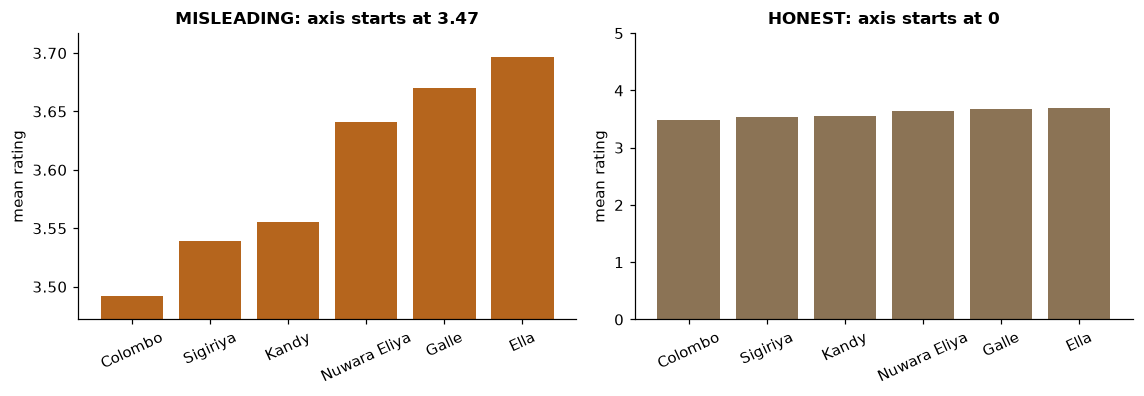

largest city difference = 0.21 stars on a 5-star scale = 4.1% of the scale. On the left it looks like a 6-fold gap between tallest and shortest bar.


In [3]:
lo, hi = city["mean"].min(), city["mean"].max()
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.7))
ax[0].bar(city.index, city["mean"], color="#b5651d"); ax[0].set_ylim(lo - .02, hi + .02); ax[0].set_title("MISLEADING: axis starts at %.2f" % (lo - .02))
ax[1].bar(city.index, city["mean"], color=ACC); ax[1].set_ylim(0, 5); ax[1].set_title("HONEST: axis starts at 0")
for a in ax: a.tick_params(axis="x", rotation=25); a.set_ylabel("mean rating")
save("w12_truncation")
print(f"largest city difference = {hi - lo:.2f} stars on a 5-star scale = {(hi - lo) / 5:.1%} of the scale. On the left it looks like a {(hi - lo + .04) / .04:.0f}-fold gap between tallest and shortest bar.")

**Common tricks to recognise (and avoid):** truncated axes on bars · dual axes that make unrelated lines "correlate" · 3-D effects and pies with many slices · cherry-picked time windows · area or size encodings that exaggerate (doubling a circle's *radius* quadruples its *area*) · colour scales that imply order where none exists.

## 2. Pick the chart for the question
| Question | Good chart | Avoid |
|---|---|---|
| Compare categories | sorted horizontal bar | pie with many slices |
| Trend over time | line | 3-D area |
| Distribution | histogram, box plot, violin | bar of means only (hides spread) |
| Relationship of two numbers | scatter (+ trend) | dual-axis line |
| Part of a whole (few parts) | stacked bar, single pie ≤ 3 slices | donut with 10 slices |
| Many groups, same measure | **small multiples** | one tangled multi-line chart |

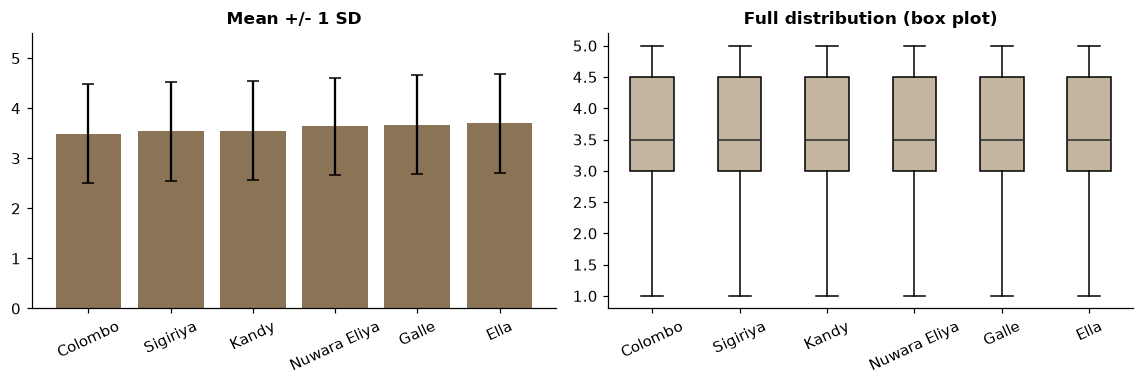

rating SD by city: {'Colombo': 0.986, 'Sigiriya': 0.983, 'Kandy': 0.995, 'Nuwara Eliya': 0.966, 'Galle': 0.991, 'Ella': 0.985}


In [4]:
# Means hide shape: same chart type, different information
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax[0].bar(city.index, city["mean"], color=ACC, yerr=city["sd"], capsize=4); ax[0].set_ylim(0, 5.5); ax[0].set_title("Mean +/- 1 SD"); ax[0].tick_params(axis="x", rotation=25)
ax[1].boxplot([df.rating[df.city == c] for c in city.index], tick_labels=city.index, patch_artist=True, boxprops=dict(facecolor=ACCL), medianprops=dict(color=CH)); ax[1].set_title("Full distribution (box plot)"); ax[1].tick_params(axis="x", rotation=25)
save("w12_distribution")
RES["sd_range"] = [float(city.sd.min()), float(city.sd.max())]; print("rating SD by city:", city.sd.to_dict())

## 3. Small multiples: many panels, one scale
One panel per city, **shared axes**, so the eye compares shape instead of decoding a legend.

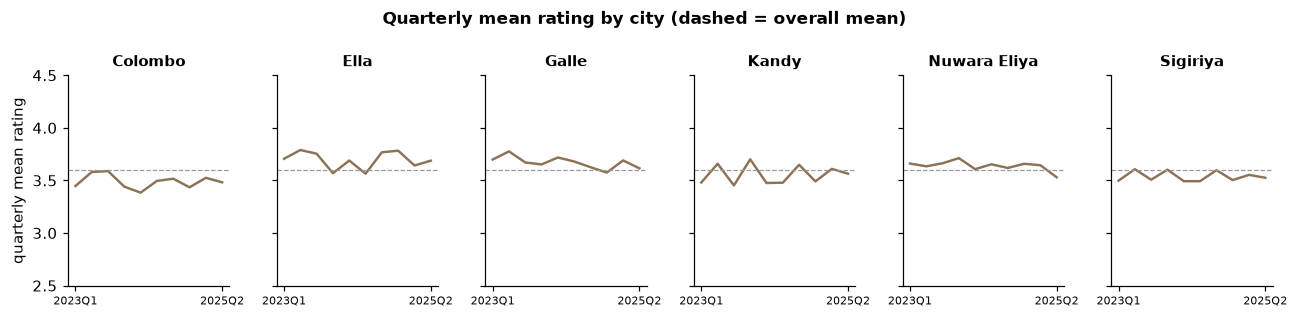

max-min swing of quarterly mean by city: {'Colombo': 0.21, 'Ella': 0.23, 'Galle': 0.2, 'Kandy': 0.25, 'Nuwara Eliya': 0.18, 'Sigiriya': 0.11}


In [5]:
m = df.groupby(["city", df.review_date.dt.to_period("Q").astype(str)]).rating.mean().unstack(0)
fig, axes = plt.subplots(1, len(m.columns), figsize=(12, 2.9), sharey=True)
for a, c in zip(axes, m.columns):
    a.plot(range(len(m)), m[c].values, color=ACC, lw=1.6); a.set_title(c, fontsize=10); a.set_ylim(2.5, 4.5); a.set_xticks([0, len(m) - 1]); a.set_xticklabels([m.index[0], m.index[-1]], fontsize=7)
    a.axhline(df.rating.mean(), color=GREY, ls="--", lw=.8)
axes[0].set_ylabel("quarterly mean rating"); fig.suptitle("Quarterly mean rating by city (dashed = overall mean)", fontweight="bold", fontsize=11); save("w12_multiples")
swing = (m.max() - m.min()).round(2); print("max-min swing of quarterly mean by city:", swing.to_dict()); RES["swing"] = swing.to_dict()

## 4. A one-screen dashboard
Top-left: the headline number. Then volume, distribution, and a ranked comparison. **Every panel answers a question**; decoration is removed.

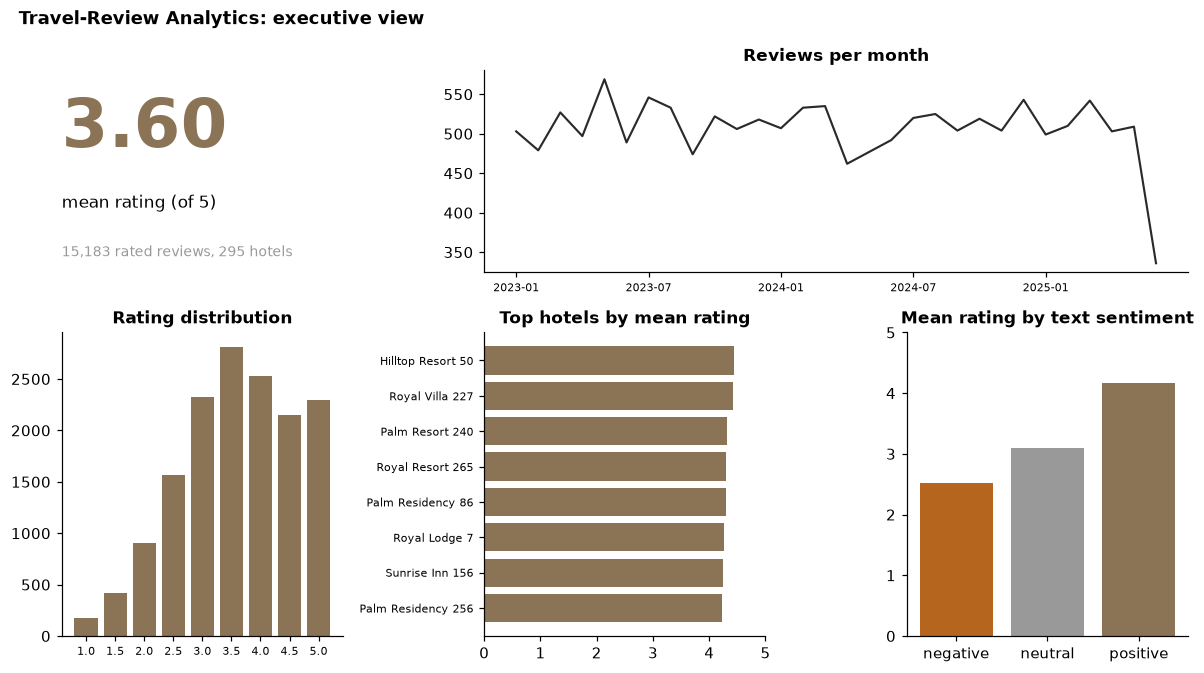

In [6]:
mon = df.groupby(df.review_date.dt.to_period("M").astype(str)).size()
fig = plt.figure(figsize=(11, 6.2)); gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.5])
a0 = fig.add_subplot(gs[0, 0]); a0.axis("off"); a0.text(0, .62, f"{df.rating.mean():.2f}", fontsize=44, fontweight="bold", color=ACC); a0.text(0, .32, "mean rating (of 5)", fontsize=11); a0.text(0, .08, f"{len(df):,} rated reviews, {df.hotel_id.nunique()} hotels", fontsize=9, color=GREY)
a1 = fig.add_subplot(gs[0, 1:]); a1.plot(range(len(mon)), mon.values, color=CH, lw=1.4); a1.set_xticks(range(0, len(mon), 6)); a1.set_xticklabels(mon.index[::6], fontsize=7); a1.set_title("Reviews per month")
a2 = fig.add_subplot(gs[1, 0]); rc = df.rating.value_counts().sort_index(); a2.bar(rc.index.astype(str), rc.values, color=ACC); a2.set_title("Rating distribution"); a2.tick_params(axis="x", labelsize=7)
a3 = fig.add_subplot(gs[1, 1]); top = hs.sort_values("avg_rating").tail(8); a3.barh(top.hotel_name, top.avg_rating, color=ACC); a3.set_xlim(0, 5); a3.set_title("Top hotels by mean rating"); a3.tick_params(axis="y", labelsize=7)
a4 = fig.add_subplot(gs[1, 2]); lab = df.groupby("label").rating.mean().reindex(["negative", "neutral", "positive"]); a4.bar(lab.index, lab.values, color=[ "#b5651d", GREY, ACC]); a4.set_ylim(0, 5); a4.set_title("Mean rating by text sentiment")
fig.suptitle("Travel-Review Analytics: executive view", fontweight="bold", x=.02, ha="left"); save("w12_dashboard")
RES["headline"] = {"mean": round(float(df.rating.mean()), 3), "n": len(df), "hotels": int(df.hotel_id.nunique())}

## 5. Quality gates: trust before you publish
A dashboard is only as good as the pipeline behind it. A **quality gate** is an automated check that *stops the pipeline* (non-zero exit) when data looks wrong, instead of silently publishing bad numbers. We read the statistics written by the Travel-Review pipeline and test each against a threshold.

In [7]:
import shutil, pathlib
src = pathlib.Path("../pipeline-project/output"); dst = pathlib.Path("data/pipeline_output"); dst.mkdir(exist_ok=True, parents=True)
for f in ["dq_ingest.json", "dq_clean.json", "summary.json"]:
    if (src / f).exists(): shutil.copy(src / f, dst / f)
ing, cln, summ = [json.load(open(dst / f)) for f in ["dq_ingest.json", "dq_clean.json", "summary.json"]]
print(ing, cln, summ, sep="\n")

{'lines_read': 300, 'lines_quarantined': 5}
{'reviews_flattened': 17460, 'after_dedup': 17266, 'rating_missing_or_invalid': 2083, 'date_unparsed': 0, 'silver_rows': 17266}
{'n_rated_reviews': 15183, 'mean_rating': 3.598, 'q1': 3.0, 'median': 3.5, 'q3': 4.5, 'corr_rating_sentiment': 0.863}


In [8]:
gates = [
    ("Corrupt-line rate below 5%",          ing["lines_quarantined"] / ing["lines_read"],                    lambda v: v < .05),
    ("Duplicate rate below 5%",             1 - cln["after_dedup"] / cln["reviews_flattened"],               lambda v: v < .05),
    ("Missing/invalid rating below 20%",    cln["rating_missing_or_invalid"] / cln["silver_rows"],           lambda v: v < .20),
    ("Unparsed dates equal 0",              cln["date_unparsed"],                                            lambda v: v == 0),
    ("Mean rating within 1-5",              summ["mean_rating"],                                             lambda v: 1 <= v <= 5),
    ("Quartiles ordered Q1 <= median <= Q3", (summ["q1"], summ["median"], summ["q3"]),                       lambda v: v[0] <= v[1] <= v[2]),
    ("Rating-sentiment correlation positive (sanity)", summ["corr_rating_sentiment"],                      lambda v: v > 0),
]
rows = [(name, (round(v, 4) if isinstance(v, float) else v), "PASS" if ok(v) else "FAIL") for name, v, ok in gates]
G = pd.DataFrame(rows, columns=["gate", "observed", "result"]); display(G)
RES["gates"] = {"passed": int((G.result == "PASS").sum()), "total": len(G), "table": G.astype(str).values.tolist()}
print(f"{RES['gates']['passed']}/{RES['gates']['total']} gates passed")

,gate,observed,result
0,Corrupt-line rate below 5%,0.0167,PASS
1,Duplicate rate below 5%,0.0111,PASS
2,Missing/invalid rating below 20%,0.1206,PASS
3,Unparsed dates equal 0,0,PASS
4,Mean rating within 1-5,3.598,PASS
5,Quartiles ordered Q1 <= median <= Q3,"(3.0, 3.5, 4.5)",PASS
6,Rating-sentiment correlation positive (sanity),0.863,PASS


7/7 gates passed


In `run_all.sh` the final step would run this check and **exit 1 on any FAIL**, so a broken upstream file never reaches the dashboard. Now we prove the gates can fail: feed them corrupted statistics.

In [9]:
bad_ing = dict(ing, lines_quarantined=60)                                          # pretend 20% of lines are corrupt
bad_cln = dict(cln, after_dedup=int(cln["reviews_flattened"] * .8), date_unparsed=37)  # pretend heavy duplicates and unparsed dates
tests = [("Corrupt-line rate", bad_ing["lines_quarantined"] / bad_ing["lines_read"], .05), ("Duplicate rate", 1 - bad_cln["after_dedup"] / bad_cln["reviews_flattened"], .05), ("Unparsed dates", bad_cln["date_unparsed"], 0)]
for name, v, thr in tests: print(f"{name:20s} observed {v:.3f}  threshold {thr}  ->", "PASS" if v <= thr and not (name == "Unparsed dates" and v > 0) else "FAIL")
RES["bad_demo_fail"] = sum(1 for name, v, thr in tests if not (v <= thr and not (name == "Unparsed dates" and v > 0)))

Corrupt-line rate    observed 0.200  threshold 0.05  -> FAIL
Duplicate rate       observed 0.200  threshold 0.05  -> FAIL
Unparsed dates       observed 37.000  threshold 0  -> FAIL


## 6. Capstone report template (20% — Travel-Review Analytics Pipeline)
Use this structure; aim for 6–8 pages plus code.

1. **Problem and users** — one paragraph: who decides what with these results?
2. **Data** — source, volume, schema, the 4 Vs, known biases and limitations.
3. **Pipeline design** — architecture diagram (bronze/silver/gold), tools, why Spark, cluster configuration (LO4).
4. **Data quality** — what you found, rules applied, counts before/after, quality gates.
5. **Analysis** — at least **two** techniques from Weeks 5–11 (e.g. predictive + text, or survival + web), each with method, result, uncertainty.
6. **Visualisation** — a dashboard following section 1–4 principles; every chart answers a stated question.
7. **Ethics and privacy** — consent, anonymisation, bias, fairness (LO2).
8. **Limitations and next steps** — what would change your conclusions?
9. **Reproducibility** — one command to rerun; versions pinned.

**Assessment lens:** correct and *explained* results over complexity; evidence of testing at scale; honest limitations.

## 7. Exercises
1. Redraw the dashboard with one additional panel that answers a question a hotel manager would ask. State the question in the title.
2. Find a misleading chart in a news article; write what is misleading and redraw it honestly.
3. Add two new quality gates (for example, rating outside 1–5 and review dates in the future) and demonstrate each failing with corrupted input.
4. Convert section 5 into a script that exits with code 1 on any failure; wire it into `run_all.sh`.

In [10]:
json.dump(RES, open("results/w12.json", "w"), indent=1); print(json.dumps(RES)[:500])

{"city": {"Colombo": 3.492, "Sigiriya": 3.539, "Kandy": 3.555, "Nuwara Eliya": 3.641, "Galle": 3.67, "Ella": 3.697}, "city_spread": 0.205, "sd_range": [0.966, 0.995], "swing": {"Colombo": 0.21, "Ella": 0.23, "Galle": 0.2, "Kandy": 0.25, "Nuwara Eliya": 0.18, "Sigiriya": 0.11}, "headline": {"mean": 3.598, "n": 15183, "hotels": 295}, "gates": {"passed": 7, "total": 7, "table": [["Corrupt-line rate below 5%", "0.0167", "PASS"], ["Duplicate rate below 5%", "0.0111", "PASS"], ["Missing/invalid rating
